# Fundamentals of Data Science - Case Study 2
## East-West Airlines: Customer Segmentation with Clustering

This notebook compares K-Means, agglomerative hierarchical clustering, and DBSCAN on the supplied East-West Airlines dataset. It excludes the customer identifier and keeps `Award?` out of the clustering inputs so redemption behavior can be used to profile (rather than define) segments.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)
BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA_PATH = BASE_DIR / "data" / "EastWestAirlines.xlsx"
OUTPUT_DIR = BASE_DIR / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

## 1. Load and audit the dataset
`ID#` is an identifier, not a behavioral measure. `Award?` is retained for after-clustering interpretation, but excluded from the distance calculation to avoid baking the redemption outcome into the segments.

In [2]:
df = pd.read_excel(DATA_PATH, sheet_name="data")
print(f"Rows: {len(df):,}; columns: {df.shape[1]}")
print(f"Missing cells: {int(df.isna().sum().sum())}")
print(f"Exact duplicate rows: {int(df.duplicated().sum())}")
print(f"Duplicate customer IDs: {int(df['ID#'].duplicated().sum())}")
display(df.head())
display(df.describe().T.round(2))

Rows: 3,999; columns: 12
Missing cells: 0
Exact duplicate rows: 0
Duplicate customer IDs: 0


,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


,count,mean,std,min,25%,50%,75%,max
ID#,3999.0,2014.82,1160.76,1.0,1010.5,2016.0,3020.5,4021.0
Balance,3999.0,73601.33,100775.66,0.0,18527.5,43097.0,92404.0,1704838.0
Qual_miles,3999.0,144.11,773.66,0.0,0.0,0.0,0.0,11148.0
cc1_miles,3999.0,2.06,1.38,1.0,1.0,1.0,3.0,5.0
cc2_miles,3999.0,1.01,0.15,1.0,1.0,1.0,1.0,3.0
cc3_miles,3999.0,1.01,0.20,1.0,1.0,1.0,1.0,5.0
Bonus_miles,3999.0,17144.85,24150.97,0.0,1250.0,7171.0,23800.5,263685.0
Bonus_trans,3999.0,11.60,9.60,0.0,3.0,12.0,17.0,86.0
Flight_miles_12mo,3999.0,460.06,1400.21,0.0,0.0,0.0,311.0,30817.0
Flight_trans_12,3999.0,1.37,3.79,0.0,0.0,0.0,1.0,53.0


## 2. Preprocessing and exploratory analysis
Several monetary, mileage, and count features are strongly right-skewed. They are log-transformed, then capped at the transformed 1st and 99th percentiles to limit leverage from extreme values without deleting potentially valuable frequent flyers. Missing values are median-imputed (the supplied dataset has none). Robust scaling is used because the distributions remain non-normal.

In [3]:
excluded = {"ID#", "Award?"}
feature_cols = [c for c in df.columns if c not in excluded]
skewed_numeric = ["Balance", "Qual_miles", "Bonus_miles", "Bonus_trans", "Flight_miles_12mo", "Flight_trans_12", "Days_since_enroll"]
X_raw = df[feature_cols].copy()
for col in skewed_numeric:
    X_raw[col] = np.log1p(X_raw[col].clip(lower=0))
    lower, upper = X_raw[col].quantile([0.01, 0.99])
    X_raw[col] = X_raw[col].clip(lower, upper)
X_imputed = SimpleImputer(strategy="median").fit_transform(X_raw)
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X_imputed)
print(f"Clustering features ({len(feature_cols)}): {feature_cols}")
print("Preprocessing complete: log1p + 1st/99th percentile cap + median imputation + RobustScaler.")

Clustering features (10): ['Balance', 'Qual_miles', 'cc1_miles', 'cc2_miles', 'cc3_miles', 'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12', 'Days_since_enroll']
Preprocessing complete: log1p + 1st/99th percentile cap + median imputation + RobustScaler.


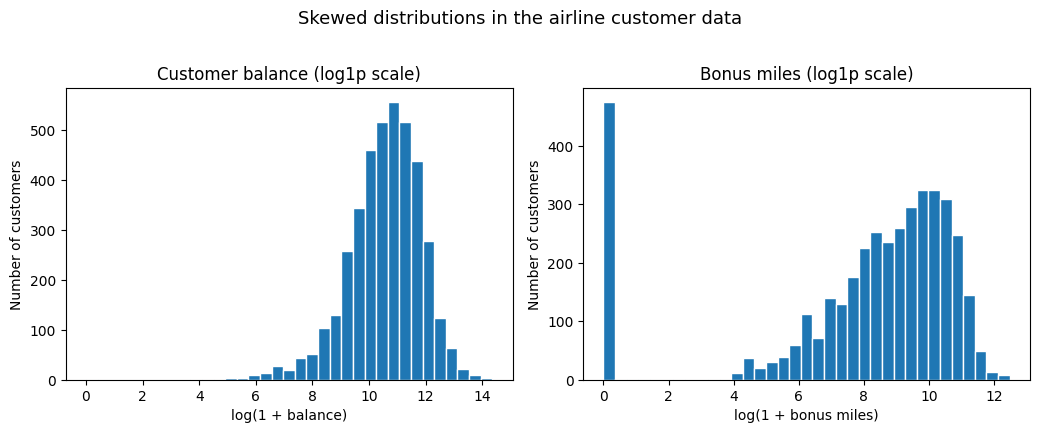

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
axes[0].hist(np.log1p(df["Balance"]), bins=35, edgecolor="white")
axes[0].set_title("Customer balance (log1p scale)")
axes[0].set_xlabel("log(1 + balance)")
axes[0].set_ylabel("Number of customers")
axes[1].hist(np.log1p(df["Bonus_miles"]), bins=35, edgecolor="white")
axes[1].set_title("Bonus miles (log1p scale)")
axes[1].set_xlabel("log(1 + bonus miles)")
axes[1].set_ylabel("Number of customers")
fig.suptitle("Skewed distributions in the airline customer data", y=1.02, fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "airline_distributions.png", dpi=180, bbox_inches="tight")
plt.show()

**EDA interpretation.** Balance and bonus miles are highly right-skewed: most customers are concentrated at lower values while a smaller group has much larger balances or rewards. The log transform and robust scaling reduce the chance that these large values dominate Euclidean distances. Capping is a robust treatment, not a claim that extreme customers are invalid.

## 3. K-Means model selection: elbow and silhouette
K-Means is evaluated for k = 2 through 8. The elbow curve measures within-cluster sum of squares (inertia); the silhouette score measures how much closer a record is to its assigned cluster than to its nearest alternative.

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,cluster_sizes
0,2,18962.205,0.659,0.561,2591.296,"3773, 226"
1,3,13163.751,0.360,0.939,2745.990,"2857, 916, 226"
2,4,9760.859,0.354,0.998,2932.511,"719, 1973, 226, 1081"
3,5,7980.264,0.330,0.969,2912.237,"724, 1246, 466, 1337, 226"
4,6,7250.797,0.328,1.095,2643.880,"1179, 1065, 226, 467, 563, 499"
5,7,6704.115,0.304,1.227,2436.556,"883, 464, 226, 439, 939, 577, 471"
6,8,6129.710,0.315,1.113,2337.035,"815, 226, 429, 463, 874, 512, 230, 450"


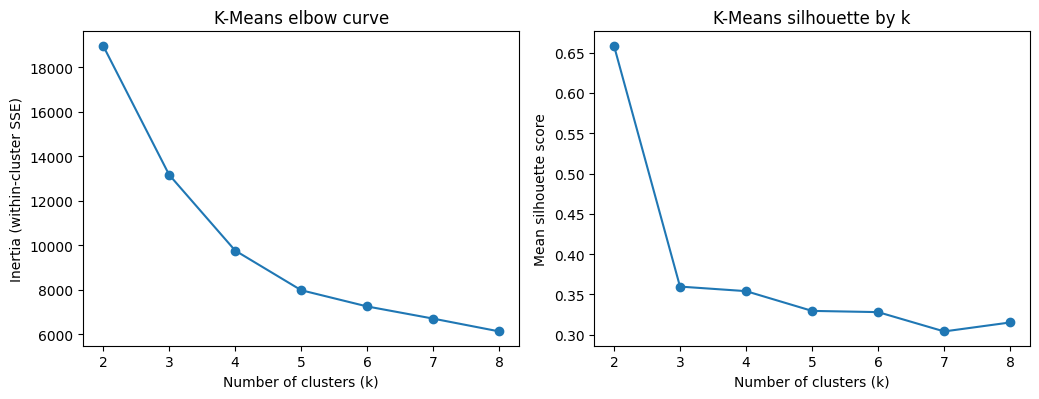

In [5]:
kmeans_rows = []
kmeans_models = {}
for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = model.fit_predict(X_scaled)
    kmeans_models[k] = (model, labels)
    kmeans_rows.append({
        "k": k,
        "inertia": float(model.inertia_),
        "silhouette": float(silhouette_score(X_scaled, labels)),
        "davies_bouldin": float(davies_bouldin_score(X_scaled, labels)),
        "calinski_harabasz": float(calinski_harabasz_score(X_scaled, labels)),
        "cluster_sizes": ", ".join(str(int(v)) for v in np.bincount(labels)),
    })
kmeans_results = pd.DataFrame(kmeans_rows)
display(kmeans_results.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.1))
axes[0].plot(kmeans_results["k"], kmeans_results["inertia"], marker="o")
axes[0].set_title("K-Means elbow curve")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (within-cluster SSE)")
axes[0].set_xticks(kmeans_results["k"])
axes[1].plot(kmeans_results["k"], kmeans_results["silhouette"], marker="o")
axes[1].set_title("K-Means silhouette by k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Mean silhouette score")
axes[1].set_xticks(kmeans_results["k"])
fig.tight_layout()
fig.savefig(FIG_DIR / "kmeans_selection.png", dpi=180, bbox_inches="tight")
plt.show()

**Model-selection interpretation.** k = 2 gives the highest silhouette score in the tested range, but it mainly separates customers with recent flight activity from the much larger remainder. k = 3 is selected for the operational segmentation because it further separates a low-reward-activity group from core reward earners while retaining the 226-customer active-flyer segment. This is a deliberate interpretability trade-off: k = 3 has lower silhouette than k = 2, so the additional segment should be validated with airline business stakeholders.

## 4. Hierarchical clustering and DBSCAN parameter experiments
Hierarchical clustering is compared for Ward, complete, and average linkage at k = 3 and 4. DBSCAN is swept over multiple `eps` and `min_samples` settings. For DBSCAN, silhouette is computed on non-noise points only and reported alongside the noise fraction; this avoids treating all noise points as one artificial cluster.

In [6]:
hier_rows = []
hier_labels = {}
for linkage in ["ward", "complete", "average"]:
    for k in [3, 4]:
        model = AgglomerativeClustering(n_clusters=k, linkage=linkage)
        labels = model.fit_predict(X_scaled)
        hier_labels[(linkage, k)] = (model, labels)
        hier_rows.append({
            "linkage": linkage,
            "k": k,
            "silhouette": float(silhouette_score(X_scaled, labels)),
            "davies_bouldin": float(davies_bouldin_score(X_scaled, labels)),
            "cluster_sizes": ", ".join(str(int(v)) for v in np.bincount(labels)),
        })
hier_results = pd.DataFrame(hier_rows)
print("Hierarchical clustering comparison")
display(hier_results.round(3))

db_rows = []
db_labels = {}
for eps in [0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.5]:
    for min_samples in [5, 10]:
        model = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=-1)
        labels = model.fit_predict(X_scaled)
        db_labels[(eps, min_samples)] = (model, labels)
        non_noise = labels != -1
        clusters = len(set(labels)) - (1 if -1 in labels else 0)
        sil = np.nan
        if clusters >= 2 and non_noise.sum() > clusters:
            try:
                sil = float(silhouette_score(X_scaled[non_noise], labels[non_noise]))
            except ValueError:
                pass
        db_rows.append({
            "eps": eps,
            "min_samples": min_samples,
            "clusters_excluding_noise": clusters,
            "noise_pct": float((~non_noise).mean() * 100),
            "silhouette_non_noise": sil,
            "cluster_sizes_top": ", ".join(str(int(v)) for v in pd.Series(labels).value_counts().head(5).tolist()),
        })
db_results = pd.DataFrame(db_rows)
print("DBSCAN parameter sweep (silhouette excludes noise records)")
display(db_results.round(3))

Hierarchical clustering comparison


,linkage,k,silhouette,davies_bouldin,cluster_sizes
0,ward,3,0.433,0.692,"3311, 226, 462"
1,ward,4,0.361,0.984,"2178, 1133, 462, 226"
2,complete,3,0.639,0.709,"3773, 211, 15"
3,complete,4,0.287,1.092,"2492, 211, 15, 1281"
4,average,3,0.639,0.709,"3773, 211, 15"
5,average,4,0.368,0.895,"3759, 211, 15, 14"


DBSCAN parameter sweep (silhouette excludes noise records)


,eps,min_samples,clusters_excluding_noise,noise_pct,silhouette_non_noise,cluster_sizes_top
0,0.75,5,9,7.552,0.136,"2140, 1043, 460, 302, 17"
1,0.75,10,4,9.552,0.160,"2127, 1020, 460, 382, 10"
2,1.00,5,8,2.976,0.020,"2609, 1091, 119, 94, 47"
3,1.00,10,7,5.351,0.022,"2607, 1084, 214, 32, 19"
4,1.25,5,4,0.975,0.627,"3751, 140, 57, 39, 12"
5,1.25,10,3,1.600,0.634,"3749, 132, 64, 54"
6,1.50,5,3,0.400,0.639,"3764, 206, 16, 13"
7,1.50,10,3,0.500,0.639,"3761, 206, 20, 12"
8,1.75,5,3,0.225,0.638,"3769, 208, 13, 9"
9,1.75,10,3,0.425,0.639,"3761, 208, 17, 13"


**Algorithm comparison interpretation.** DBSCAN with `eps=1.5` and `min_samples=10` identifies three dense groups and marks about 0.5% of customers as noise. This is useful for surfacing unusual profiles, but DBSCAN is sensitive to distance and density settings. Hierarchical complete linkage can have a deceptively high silhouette while isolating a very small group; cluster size and interpretability must be read alongside the score.

## 5. Compare candidate algorithms and select a working segmentation
A 3-cluster K-Means solution is retained for business profiling. Ward hierarchical clustering and DBSCAN are included as comparisons. Silhouette values are not directly equivalent for DBSCAN because its value excludes noise points.

In [7]:
selected_km_model, selected_km_labels = kmeans_models[3]
selected_hier_model, selected_hier_labels = hier_labels[("ward", 3)]
selected_db_model, selected_db_labels = db_labels[(1.5, 10)]
comparison_rows = [
    {"algorithm": "K-Means (k=3)", "clusters": int(len(np.unique(selected_km_labels))), "noise_pct": 0.0,
     "silhouette": float(silhouette_score(X_scaled, selected_km_labels)),
     "davies_bouldin": float(davies_bouldin_score(X_scaled, selected_km_labels)),
     "calinski_harabasz": float(calinski_harabasz_score(X_scaled, selected_km_labels))},
    {"algorithm": "Hierarchical Ward (k=3)", "clusters": int(len(np.unique(selected_hier_labels))), "noise_pct": 0.0,
     "silhouette": float(silhouette_score(X_scaled, selected_hier_labels)),
     "davies_bouldin": float(davies_bouldin_score(X_scaled, selected_hier_labels)),
     "calinski_harabasz": float(calinski_harabasz_score(X_scaled, selected_hier_labels))},
    {"algorithm": "Hierarchical complete (k=3)", "clusters": int(len(np.unique(hier_labels[("complete", 3)][1]))), "noise_pct": 0.0,
     "silhouette": float(silhouette_score(X_scaled, hier_labels[("complete", 3)][1])),
     "davies_bouldin": float(davies_bouldin_score(X_scaled, hier_labels[("complete", 3)][1])),
     "calinski_harabasz": float(calinski_harabasz_score(X_scaled, hier_labels[("complete", 3)][1]))},
    {"algorithm": "DBSCAN (eps=1.5, min_samples=10)", "clusters": int(len(set(selected_db_labels)) - (-1 in selected_db_labels)),
     "noise_pct": float((selected_db_labels == -1).mean() * 100),
     "silhouette": float(silhouette_score(X_scaled[selected_db_labels != -1], selected_db_labels[selected_db_labels != -1])),
     "davies_bouldin": np.nan, "calinski_harabasz": np.nan},
]
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(3))

# Profile the clusters from the two non-K-Means alternatives as well. The redemption flag remains a profile field only.
def build_alternative_profiles(algorithm_name, labels):
    prof = df.copy()
    prof["cluster_label"] = labels
    temp = prof.groupby("cluster_label").agg(
        customers=("ID#", "size"),
        median_balance=("Balance", "median"),
        median_bonus_miles=("Bonus_miles", "median"),
        mean_flight_miles_12mo=("Flight_miles_12mo", "mean"),
        award_rate_pct=("Award?", lambda values: values.mean() * 100),
    ).reset_index()
    labels_non_noise = temp[temp["cluster_label"] != -1]
    active_label = int(labels_non_noise.loc[labels_non_noise["mean_flight_miles_12mo"].idxmax(), "cluster_label"])
    remaining = labels_non_noise[labels_non_noise["cluster_label"] != active_label]
    low_label = int(remaining.loc[remaining["median_bonus_miles"].idxmin(), "cluster_label"])
    rows = []
    for _, row in temp.iterrows():
        label = int(row["cluster_label"])
        if label == -1:
            profile_name = "Noise / unusual profiles"
        elif label == active_label:
            profile_name = "Active flyers"
        elif label == low_label and row["median_bonus_miles"] == remaining["median_bonus_miles"].min():
            profile_name = "Low reward activity"
        else:
            profile_name = "Core reward earners"
        rows.append({
            "algorithm": algorithm_name,
            "segment_interpretation": profile_name,
            "cluster_label": label,
            "customers": int(row["customers"]),
            "median_balance": float(row["median_balance"]),
            "median_bonus_miles": float(row["median_bonus_miles"]),
            "mean_flight_miles_12mo": float(row["mean_flight_miles_12mo"]),
            "award_rate_pct": float(row["award_rate_pct"]),
        })
    return rows

alternative_profiles = (
    build_alternative_profiles("Hierarchical Ward (k=3)", selected_hier_labels)
    + build_alternative_profiles("DBSCAN (eps=1.5, min_samples=10)", selected_db_labels)
)
alternative_profiles_df = pd.DataFrame(alternative_profiles)
print("Alternative-algorithm cluster profile cross-check")
display(alternative_profiles_df.round(2))

,algorithm,clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz
0,K-Means (k=3),3,0.0,0.360,0.939,2745.990
1,Hierarchical Ward (k=3),3,0.0,0.433,0.692,2586.147
2,Hierarchical complete (k=3),3,0.0,0.639,0.709,1341.793
3,"DBSCAN (eps=1.5, min_samples=10)",3,0.5,0.639,NaN,NaN


Alternative-algorithm cluster profile cross-check


,algorithm,segment_interpretation,cluster_label,customers,median_balance,median_bonus_miles,mean_flight_miles_12mo,award_rate_pct
0,Hierarchical Ward (k=3),Core reward earners,0,3311,47557.0,9680.0,438.25,39.20
1,Hierarchical Ward (k=3),Active flyers,1,226,66838.5,11875.0,1720.06,64.60
2,Hierarchical Ward (k=3),Low reward activity,2,462,16039.5,0.0,0.00,8.01
3,"DBSCAN (eps=1.5, min_samples=10)",Noise / unusual profiles,-1,20,83564.5,62913.5,788.20,50.00
4,"DBSCAN (eps=1.5, min_samples=10)",Core reward earners,0,3761,40893.0,6654.0,384.40,35.31
5,"DBSCAN (eps=1.5, min_samples=10)",Active flyers,1,206,76223.5,12898.5,1836.26,69.42
6,"DBSCAN (eps=1.5, min_samples=10)",Low reward activity,2,12,26742.0,0.0,0.00,0.00


**Alternative cluster interpretation.** Ward hierarchical clustering produces the same broad pattern as the chosen K-Means solution: a core group, a group with the most recent flying, and a low-reward-activity group. DBSCAN identifies a similar active-flyer group and a 12-customer low-reward group, while marking 20 profiles as noise. Noise points have unusually high median bonus miles in this run and should be investigated rather than automatically labelled as errors.

## 6. Interpret the K-Means segments
Cluster labels are arbitrary. The following descriptive names are assigned from observed profiles: active flyers have the highest mean flight miles; low reward activity has the lowest median bonus miles among the remaining groups; the final group is described as core reward earners. `Award?` is used only here as a profile measure, not as a clustering input.

,segment,customers,median_balance,median_bonus_miles,median_bonus_transactions,mean_flight_miles_12mo,median_days_since_enrollment,award_rate_pct
0,Core reward earners,2857,56756.0,13495.0,14.0,501.49,4328.0,43.3
1,Low reward activity,916,14079.0,0.0,0.0,19.95,3010.0,10.7
2,Active flyers,226,66838.5,11875.0,14.0,1720.06,4582.0,64.6


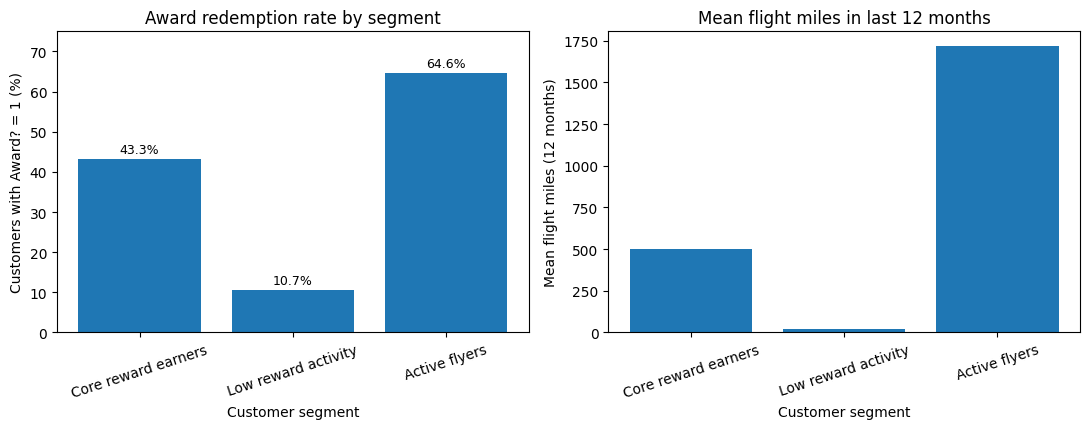

In [8]:
clustered = df.copy()
clustered["cluster_id"] = selected_km_labels
raw_profiles = clustered.groupby("cluster_id").agg(
    customers=("ID#", "size"),
    median_balance=("Balance", "median"),
    median_bonus_miles=("Bonus_miles", "median"),
    median_bonus_transactions=("Bonus_trans", "median"),
    mean_flight_miles_12mo=("Flight_miles_12mo", "mean"),
    median_flight_trans_12mo=("Flight_trans_12", "median"),
    median_days_since_enrollment=("Days_since_enroll", "median"),
    award_rate=("Award?", "mean"),
).reset_index()
active_id = int(raw_profiles.loc[raw_profiles["mean_flight_miles_12mo"].idxmax(), "cluster_id"])
remaining = raw_profiles[raw_profiles["cluster_id"] != active_id]
low_id = int(remaining.loc[remaining["median_bonus_miles"].idxmin(), "cluster_id"])
core_id = int([v for v in raw_profiles["cluster_id"] if v not in [active_id, low_id]][0])
segment_names = {active_id: "Active flyers", low_id: "Low reward activity", core_id: "Core reward earners"}
clustered["segment"] = clustered["cluster_id"].map(segment_names)
raw_profiles["segment"] = raw_profiles["cluster_id"].map(segment_names)
raw_profiles["award_rate_pct"] = raw_profiles["award_rate"] * 100
profile_cols = ["segment", "customers", "median_balance", "median_bonus_miles", "median_bonus_transactions", "mean_flight_miles_12mo", "median_days_since_enrollment", "award_rate_pct"]
profiles = raw_profiles[profile_cols].sort_values("customers", ascending=False).reset_index(drop=True)
display(profiles.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
order = profiles["segment"].tolist()
plot_prof = profiles.set_index("segment").loc[order]
axes[0].bar(order, plot_prof["award_rate_pct"])
axes[0].set_title("Award redemption rate by segment")
axes[0].set_xlabel("Customer segment")
axes[0].set_ylabel("Customers with Award? = 1 (%)")
axes[0].set_ylim(0, 75)
axes[0].tick_params(axis="x", rotation=18)
for i, v in enumerate(plot_prof["award_rate_pct"]):
    axes[0].text(i, v + 1.5, f"{v:.1f}%", ha="center", fontsize=9)
axes[1].bar(order, plot_prof["mean_flight_miles_12mo"])
axes[1].set_title("Mean flight miles in last 12 months")
axes[1].set_xlabel("Customer segment")
axes[1].set_ylabel("Mean flight miles (12 months)")
axes[1].tick_params(axis="x", rotation=18)
fig.tight_layout()
fig.savefig(FIG_DIR / "cluster_profiles.png", dpi=180, bbox_inches="tight")
plt.show()

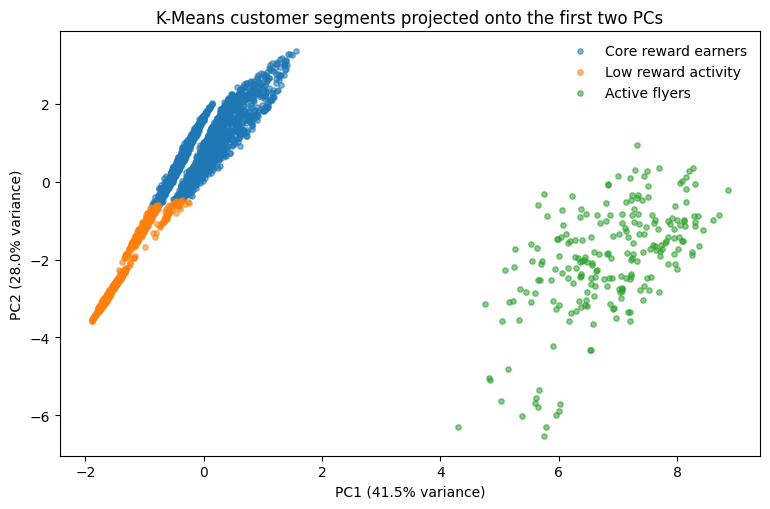

In [9]:
projector = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = projector.fit_transform(X_scaled)
fig, ax = plt.subplots(figsize=(7.8, 5.2))
for cid in sorted(np.unique(selected_km_labels)):
    mask = selected_km_labels == cid
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=15, alpha=0.55, label=segment_names[int(cid)])
ax.set_title("K-Means customer segments projected onto the first two PCs")
ax.set_xlabel(f"PC1 ({projector.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({projector.explained_variance_ratio_[1]*100:.1f}% variance)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "kmeans_pca.png", dpi=180, bbox_inches="tight")
plt.show()

**Segment interpretation.** The low-reward-activity group is characterized by a lower balance, little or no median bonus accumulation, and the lowest award rate. Core reward earners have higher median balances and bonus miles. Active flyers have the greatest recent flight activity and the highest award-redemption rate. These are descriptive patterns, not causal claims, and segment names should be validated with operational stakeholders before campaigns are launched.

## 7. Conclusion and limitations
The dataset supports a practical three-segment K-Means view, although k = 2 has a stronger silhouette score. Scaling and skew treatment materially affect distance-based algorithms; another encoding or a different feature set can change the partitions. The dataset is a snapshot without customer demographics, spend margin, or future retention outcomes, so it cannot by itself establish campaign profitability or causal drivers.

In [10]:
print("Key conclusion:")
print("- K-Means k=2 maximizes silhouette in the tested range, but k=3 offers more actionable profiles.")
print("- DBSCAN eps=1.5/min_samples=10 creates three dense clusters and a small noise set.")
print("- Use clusters as hypotheses for customer engagement, not as proven predictors of future value.")
summary = {
    "rows": int(len(df)),
    "columns": int(df.shape[1]),
    "missing_cells": int(df.isna().sum().sum()),
    "duplicates": int(df.duplicated().sum()),
    "kmeans_results": kmeans_results.to_dict(orient="records"),
    "hierarchical_results": hier_results.to_dict(orient="records"),
    "dbscan_results": db_results.replace({np.nan: None}).to_dict(orient="records"),
    "comparison": comparison.replace({np.nan: None}).to_dict(orient="records"),
    "alternative_profiles": alternative_profiles_df.replace({np.nan: None}).to_dict(orient="records"),
    "profiles": profiles.replace({np.nan: None}).to_dict(orient="records"),
    "selected_k": 3,
    "best_silhouette_k": int(kmeans_results.loc[kmeans_results["silhouette"].idxmax(), "k"]),
}
with open(OUTPUT_DIR / "results_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=lambda o: float(o) if isinstance(o, (np.floating,)) else int(o) if isinstance(o, (np.integer,)) else str(o))
print(f"Saved figures and result summary under: {OUTPUT_DIR}")

Key conclusion:
- K-Means k=2 maximizes silhouette in the tested range, but k=3 offers more actionable profiles.
- DBSCAN eps=1.5/min_samples=10 creates three dense clusters and a small noise set.
- Use clusters as hypotheses for customer engagement, not as proven predictors of future value.
Saved figures and result summary under: /mnt/data/fds_work/case2/outputs
